# Viewing OpenBiomechanics full-signal and C3D data (pitching)

1. Clone the repository and download the large pitching files from GitHub Releases
2. **Full signal:** joint velocities, joint angles and energy flow → one pitch, then fast vs. slow throwers
3. **C3D:** raw 3D marker positions → a 3D view and an animation of one pitch
4. **Stick figure** built from the markers, as still frames and an animation
5. **Documentation:** column definitions and sign conventions from the repository

**License reminder:** CC BY-NC-SA 4.0 (non-commercial), plus a ban on use by anyone associated with a professional sports organization or financial analysis firm without a paid license. Fine for personal learning.

The column and file names of the release were not verified by hand, so each step prints what it finds. If a name lookup fails, the printout shows the real names to put in.

In [1]:
!git clone --depth 1 https://github.com/drivelineresearch/openbiomechanics.git /content/openbiomechanics
!pip -q install ezc3d

import json, os, sys, shutil, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path("/content/openbiomechanics")
PITCH_DIR = REPO / "baseball_pitching" / "data"
C3D_DIR = PITCH_DIR / "c3d"
FS_DIR = PITCH_DIR / "full_sig"
STAGE = Path("/content/obp_downloads")
for d in (C3D_DIR, FS_DIR, STAGE):
    d.mkdir(parents=True, exist_ok=True)

os.chdir(REPO); sys.path.insert(0, str(REPO))
import obp
meta = obp.load_metadata("pitching")
print(meta.shape)
meta.head()

Cloning into '/content/openbiomechanics'...
remote: Enumerating objects: 276, done.
remote: Counting objects: 100% (276/276), done.
remote: Compressing objects: 100% (256/256), done.
remote: Total 276 (delta 13), reused 227 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (276/276), 26.33 MiB | 17.59 MiB/s, done.
Resolving deltas: 100% (13/13), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 11.4 MB/s eta 0:00:00
(411, 10)


,user,session,session_pitch,session_mass_kg,session_height_m,age_yrs,playing_level,pitch_speed_mph,filename_new,modelname_new
0,750,1031,1031_2,110.6784,1.9304,21.40,college,90.4,000750_001031_76_244_013_FF_904.c3d,000750_001031_model.c3d
1,750,1031,1031_3,110.6784,1.9304,21.40,college,90.4,000750_001031_76_244_014_FF_904.c3d,000750_001031_model.c3d
2,774,1097,1097_1,101.1528,1.9304,19.41,college,77.6,000774_001097_76_223_001_FF_776.c3d,000774_001097_model.c3d
3,774,1097,1097_2,101.1528,1.9304,19.41,college,77.0,000774_001097_76_223_005_FF_770.c3d,000774_001097_model.c3d
4,774,1097,1097_3,101.1528,1.9304,19.41,college,76.1,000774_001097_76_223_006_FF_761.c3d,000774_001097_model.c3d


## 1. Download the pitching release files

The repository's own downloader needs the GitHub CLI and a login. This cell uses GitHub's public API instead (no account needed): it lists the files in the `dataset-v1` release and downloads the ones with "pitch" in the name.

In [2]:
def get_release(tag="dataset-v1"):
    base = "https://api.github.com/repos/drivelineresearch/openbiomechanics/releases"
    try:
        return json.load(urllib.request.urlopen(f"{base}/tags/{tag}"))
    except Exception as e:
        print(f"Tag {tag!r} not found ({e}). Available releases:")
        for r in json.load(urllib.request.urlopen(base)):
            print("  ", r["tag_name"], "-", r["name"])
        raise

release = get_release()
print("All files in the release:")
for a in release["assets"]:
    print(f'  {a["name"]:<55} {a["size"] / 1e6:8.1f} MB')

wanted = [a for a in release["assets"] if "pitch" in a["name"].lower()]
print(f"\nDownloading {len(wanted)} pitching files "
      f'({sum(a["size"] for a in wanted) / 1e6:.0f} MB)...')
for a in wanted:
    dest = STAGE / a["name"]
    if dest.exists() and dest.stat().st_size == a["size"]:
        print("  already have", a["name"]); continue
    urllib.request.urlretrieve(a["browser_download_url"], dest)
    print("  downloaded", a["name"])

All files in the release:
  hitting_c3d.zip                                            432.3 MB
  hitting_force_plate.zip                                     36.3 MB
  hitting_joint_angles.zip                                    65.7 MB
  hitting_joint_velos.zip                                     88.7 MB
  hitting_landmarks.zip                                       65.8 MB
  pitching_c3d.zip                                           184.6 MB
  pitching_energy_flow.zip                                    42.4 MB
  pitching_forces_moments.zip                                 87.3 MB
  pitching_force_plate.zip                                    18.5 MB
  pitching_joint_angles.zip                                   35.6 MB
  pitching_joint_velos.zip                                    37.3 MB
  pitching_landmarks.zip                                      33.0 MB

  downloaded pitching_c3d.zip
  downloaded pitching_energy_flow.zip
  downloaded pitching_forces_moments.zip
  downloaded pitching_fo

Sort the downloads: archives holding `.c3d` files are extracted into `data/c3d/`; full-signal archives go to `data/full_sig/` (still zipped, extracted later one table at a time, as the project recommends).

In [4]:
for f in sorted(STAGE.iterdir()):
    if not zipfile.is_zipfile(f):
        shutil.copy(f, FS_DIR / f.name); continue
    with zipfile.ZipFile(f) as z:
        names = z.namelist()
        if any(n.lower().endswith(".c3d") for n in names):
            z.extractall(C3D_DIR); kind = "C3D -> data/c3d"
        elif any(n.lower().endswith(".zip") for n in names):
            z.extractall(FS_DIR); kind = "zip of tables -> data/full_sig"
        else:
            shutil.copy(f, FS_DIR / f.name); kind = "table archive -> data/full_sig"
    print(f"{f.name:<55} {kind}")

c3d_files = sorted(C3D_DIR.rglob("*.c3d"))
fs_files = sorted(p for p in FS_DIR.rglob("*") if p.suffix in (".zip", ".csv"))
print(f"\n{len(c3d_files)} C3D files")
print("Full-signal files:", *[p.relative_to(FS_DIR) for p in fs_files], sep="\n  ")

pitching_c3d.zip                                        C3D -> data/c3d
pitching_energy_flow.zip                                table archive -> data/full_sig
pitching_force_plate.zip                                table archive -> data/full_sig
pitching_forces_moments.zip                             table archive -> data/full_sig
pitching_joint_angles.zip                               table archive -> data/full_sig
pitching_joint_velos.zip                                table archive -> data/full_sig
pitching_landmarks.zip                                  table archive -> data/full_sig

511 C3D files
Full-signal files:
  pitching_energy_flow.zip
  pitching_force_plate.zip
  pitching_forces_moments.zip
  pitching_joint_angles.zip
  pitching_joint_velos.zip
  pitching_landmarks.zip


## 2. Full signal

Six tables: `joint_angles`, `joint_velos`, `forces_moments`, `energy_flow`, `force_plate`, `landmarks`. Rows = one time point of one pitch; they join on `session_pitch` + `time`. Marker-based tables are sampled at 360 Hz (force plates at 1,080 Hz), and event times (foot plant, max external rotation, ball release, ...) are included as columns.

In [5]:
EXTRACT = Path("/content/full_sig_csv"); EXTRACT.mkdir(exist_ok=True)

def load_table(name):
    hits = [p for p in FS_DIR.rglob("*") if name in p.name and p.suffix in (".zip", ".csv")]
    if not hits:
        raise FileNotFoundError(f"No file containing {name!r} in {FS_DIR}")
    p = hits[0]
    if p.suffix == ".zip":
        with zipfile.ZipFile(p) as z:
            csvs = [n for n in z.namelist() if n.endswith(".csv")]
            z.extract(csvs[0], EXTRACT)
            p = EXTRACT / csvs[0]
    return pd.read_csv(p)

velos = load_table("joint_velos")
print(velos.shape, "|", velos["session_pitch"].nunique(), "pitches")
print("\nColumns:", list(velos.columns))

(247709, 47) | 411 pitches

Columns: ['session_pitch', 'time', 'elbow_velo_x', 'elbow_velo_y', 'elbow_velo_z', 'rear_hip_velo_x', 'rear_hip_velo_y', 'rear_hip_velo_z', 'rear_knee_velo_x', 'rear_knee_velo_y', 'rear_knee_velo_z', 'shoulder_velo_x', 'shoulder_velo_y', 'shoulder_velo_z', 'wrist_velo_x', 'wrist_velo_y', 'wrist_velo_z', 'pelvis_velo_x', 'pelvis_velo_y', 'pelvis_velo_z', 'glove_elbow_velo_x', 'glove_elbow_velo_y', 'glove_elbow_velo_z', 'lead_hip_velo_x', 'lead_hip_velo_y', 'lead_hip_velo_z', 'lead_knee_velo_x', 'lead_knee_velo_y', 'lead_knee_velo_z', 'glove_shoulder_velo_x', 'glove_shoulder_velo_y', 'glove_shoulder_velo_z', 'glove_wrist_velo_x', 'glove_wrist_velo_y', 'glove_wrist_velo_z', 'torso_velo_x', 'torso_velo_y', 'torso_velo_z', 'torso_pelvis_velo_x', 'torso_pelvis_velo_y', 'torso_pelvis_velo_z', 'pkh_time', 'fp_10_time', 'fp_100_time', 'MER_time', 'BR_time', 'MIR_time']


In [6]:
def find_col(df, *must, exclude=()):
    # first column whose name contains every word in `must` and none in `exclude`
    for c in df.columns:
        lc = c.lower()
        if all(m in lc for m in must) and not any(x in lc for x in exclude):
            return c
    return None

# Edit these if the printout shows a better match
SEGMENTS = {
    "pelvis rotation":           find_col(velos, "pelvis", "_z", exclude=("torso_pelvis",)),
    "torso rotation":            find_col(velos, "torso", "_z", exclude=("torso_pelvis",)),
    "elbow extension":           find_col(velos, "elbow", "_x", exclude=("glove",)),
    "shoulder internal rotation": find_col(velos, "shoulder", "_z", exclude=("glove",)),
}
EVENT_COLS = [c for c in velos.columns if c != "time" and "time" in c.lower()]
BR_COL = next((c for c in EVENT_COLS if "br" in c.lower() or "release" in c.lower()), None)
print("Signals:", SEGMENTS)
print("Event columns:", EVENT_COLS, "| ball release:", BR_COL)

Signals: {'pelvis rotation': 'pelvis_velo_z', 'torso rotation': 'torso_velo_z', 'elbow extension': 'elbow_velo_x', 'shoulder internal rotation': 'shoulder_velo_z'}
Event columns: ['pkh_time', 'fp_10_time', 'fp_100_time', 'MER_time', 'BR_time', 'MIR_time'] | ball release: BR_time


### One pitch: the kinematic sequence
In an efficient delivery, peak rotation speed moves up the body in order: pelvis, then torso, then the arm.

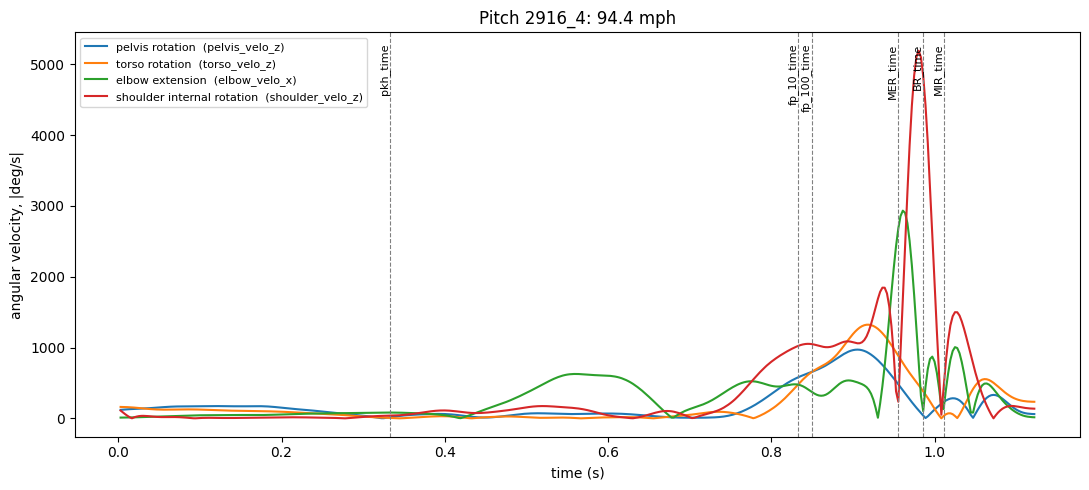

In [7]:
speed = meta.set_index("session_pitch")["pitch_speed_mph"]
pitch_id = speed.idxmax() if speed.idxmax() in set(velos["session_pitch"]) else velos["session_pitch"].iloc[0]
one = velos[velos["session_pitch"] == pitch_id].sort_values("time")

fig, ax = plt.subplots(figsize=(11, 5))
for label, col in SEGMENTS.items():
    if col:
        ax.plot(one["time"], one[col].abs(), label=f"{label}  ({col})")
for ev in EVENT_COLS:
    t = one[ev].iloc[0]
    if pd.notna(t):
        ax.axvline(t, color="gray", ls="--", lw=0.8)
        ax.text(t, ax.get_ylim()[1] * 0.97, ev, rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel("time (s)"); ax.set_ylabel("angular velocity, |deg/s|")
ax.set_title(f"Pitch {pitch_id}: {speed.get(pitch_id, float('nan')):.1f} mph")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Fast vs. slow throwers
Every pitch is re-timed so 0 = ball release, then averaged within the fastest and slowest quarters of pitches (mean ± 1 SD).

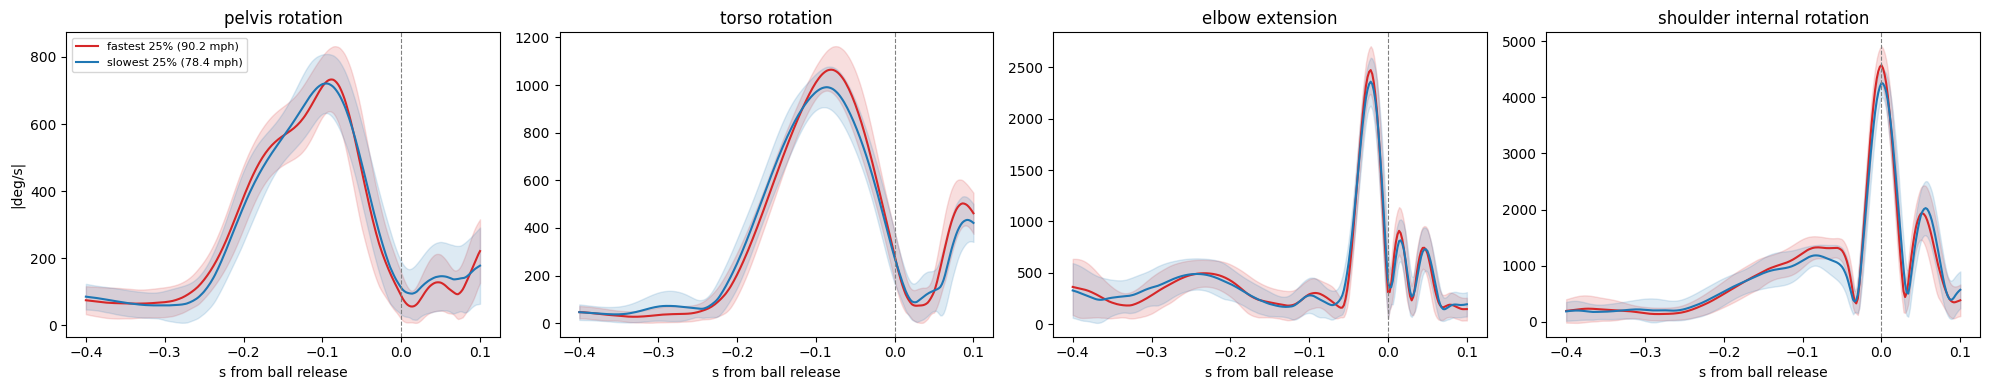

In [8]:
grid = np.linspace(-0.4, 0.1, 251)   # seconds relative to ball release

def aligned(col, ids):
    out = []
    for pid in ids:
        p = velos[velos["session_pitch"] == pid].sort_values("time")
        if p.empty or pd.isna(p[BR_COL].iloc[0]):
            continue
        out.append(np.interp(grid, p["time"] - p[BR_COL].iloc[0], p[col].abs(),
                             left=np.nan, right=np.nan))
    return np.array(out)

ids = speed[speed.index.isin(velos["session_pitch"])]
fast, slow = ids[ids >= ids.quantile(0.75)].index, ids[ids <= ids.quantile(0.25)].index
plot_segs = {k: v for k, v in SEGMENTS.items() if v}

if BR_COL is None:
    print("No ball-release column found: set BR_COL from the event columns printed above.")
else:
    fig, axes = plt.subplots(1, len(plot_segs), figsize=(5 * len(plot_segs), 4), sharex=True)
    for ax, (label, col) in zip(np.atleast_1d(axes), plot_segs.items()):
        for grp, name, color in [(fast, f"fastest 25% ({ids[fast].mean():.1f} mph)", "tab:red"),
                                 (slow, f"slowest 25% ({ids[slow].mean():.1f} mph)", "tab:blue")]:
            a = aligned(col, grp)
            m, s = np.nanmean(a, 0), np.nanstd(a, 0)
            ax.plot(grid, m, color=color, label=name)
            ax.fill_between(grid, m - s, m + s, color=color, alpha=0.15)
        ax.axvline(0, color="gray", ls="--", lw=0.8)
        ax.set_title(label); ax.set_xlabel("s from ball release")
    np.atleast_1d(axes)[0].set_ylabel("|deg/s|"); np.atleast_1d(axes)[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

### Joint angles
Same loading pattern. Below: hip-shoulder separation, shoulder external rotation (layback) and lead-knee flexion for the same pitch, then fast vs. slow throwers. Sign conventions are explained in section 5.

(247709, 53)
Columns: ['session_pitch', 'time', 'rear_ankle_angle_x', 'rear_ankle_angle_y', 'rear_ankle_angle_z', 'elbow_angle_x', 'elbow_angle_y', 'elbow_angle_z', 'rear_hip_angle_x', 'rear_hip_angle_y', 'rear_hip_angle_z', 'rear_knee_angle_x', 'rear_knee_angle_y', 'rear_knee_angle_z', 'shoulder_angle_x', 'shoulder_angle_y', 'shoulder_angle_z', 'wrist_angle_x', 'wrist_angle_y', 'wrist_angle_z', 'pelvis_angle_x', 'pelvis_angle_y', 'pelvis_angle_z', 'lead_ankle_angle_x', 'lead_ankle_angle_y', 'lead_ankle_angle_z', 'glove_elbow_angle_x', 'glove_elbow_angle_y', 'glove_elbow_angle_z', 'lead_hip_angle_x', 'lead_hip_angle_y', 'lead_hip_angle_z', 'lead_knee_angle_x', 'lead_knee_angle_y', 'lead_knee_angle_z', 'glove_shoulder_angle_x', 'glove_shoulder_angle_y', 'glove_shoulder_angle_z', 'glove_wrist_angle_x', 'glove_wrist_angle_y', 'glove_wrist_angle_z', 'torso_angle_x', 'torso_angle_y', 'torso_angle_z', 'torso_pelvis_angle_x', 'torso_pelvis_angle_y', 'torso_pelvis_angle_z', 'pkh_time', 'fp_10_

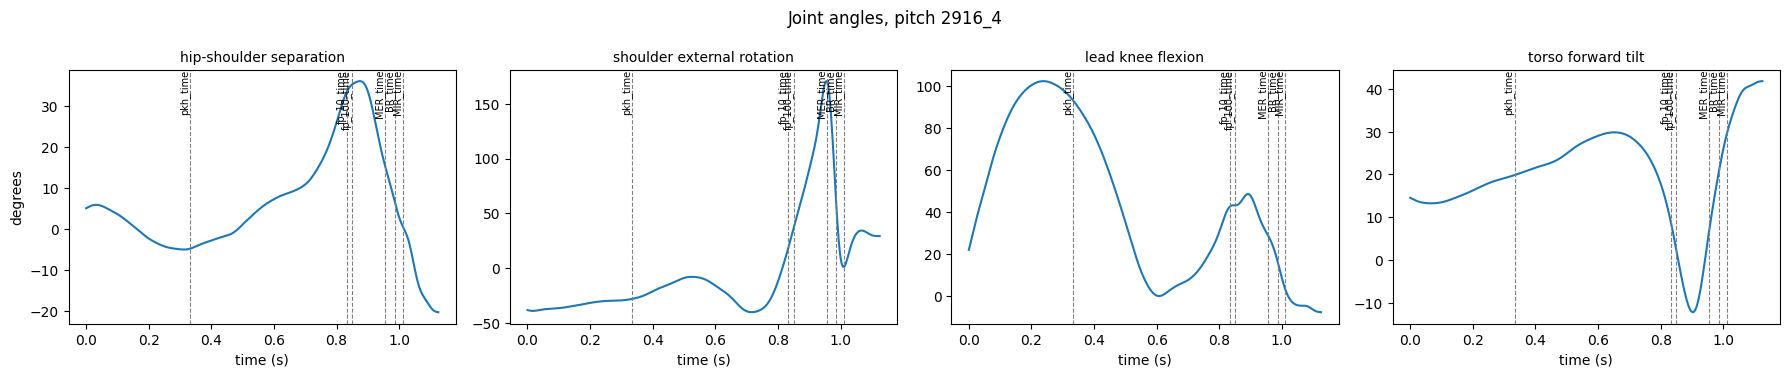

In [9]:
angles = load_table("joint_angles")
print(angles.shape)
print("Columns:", list(angles.columns))

# Edit these if the printout shows a better match
ANGLES = {
    "hip-shoulder separation":    find_col(angles, "torso_pelvis", "_z"),
    "shoulder external rotation": find_col(angles, "shoulder", "_z", exclude=("glove",)),
    "lead knee flexion":          find_col(angles, "lead_knee", "_x"),
    "torso forward tilt":         find_col(angles, "torso", "_x", exclude=("torso_pelvis",)),
}
print("Picked:", ANGLES)

def event_lines(ax, table, pid):
    p = table[table["session_pitch"] == pid]
    for ev in [c for c in table.columns if c != "time" and "time" in c.lower()]:
        t = p[ev].iloc[0]
        if pd.notna(t):
            ax.axvline(t, color="gray", ls="--", lw=0.8)
            ax.text(t, 1.0, ev, transform=ax.get_xaxis_transform(), rotation=90,
                    va="top", ha="right", fontsize=7)

one_a = angles[angles["session_pitch"] == pitch_id].sort_values("time")
plot_a = {k: v for k, v in ANGLES.items() if v}
fig, axes = plt.subplots(1, len(plot_a), figsize=(4.5 * len(plot_a), 3.8))
for ax, (label, col) in zip(np.atleast_1d(axes), plot_a.items()):
    ax.plot(one_a["time"], one_a[col])
    event_lines(ax, angles, pitch_id)
    ax.set_title(label, fontsize=10); ax.set_xlabel("time (s)")
np.atleast_1d(axes)[0].set_ylabel("degrees")
plt.suptitle(f"Joint angles, pitch {pitch_id}"); plt.tight_layout(); plt.show()

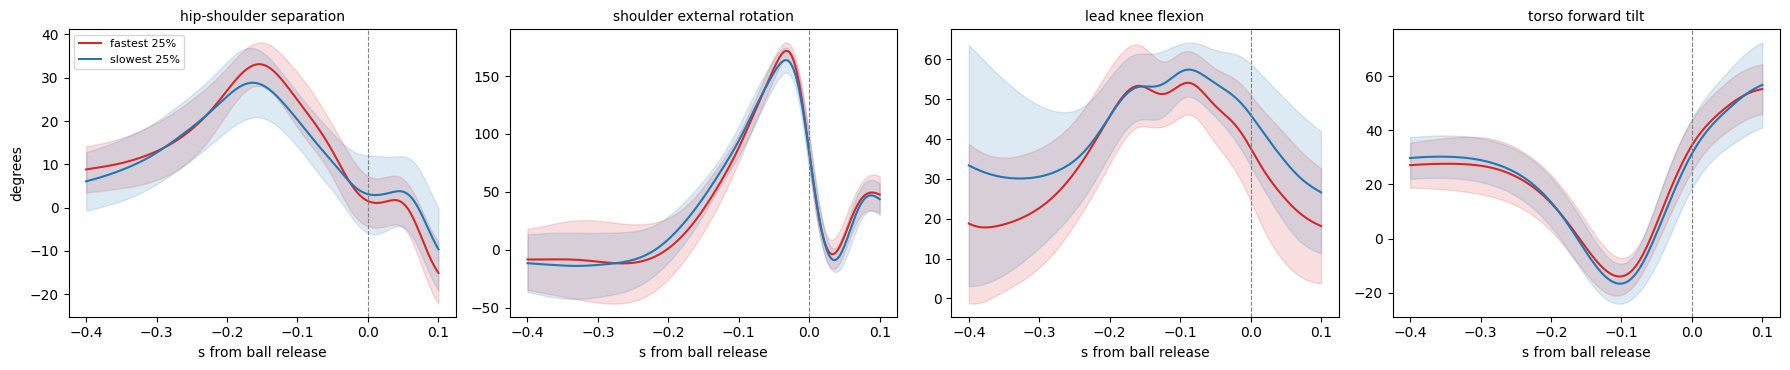

In [10]:
def aligned_table(table, col, ids, br_col, absolute=False):
    # each pitch re-timed so 0 = ball release, interpolated onto `grid`
    out = []
    for pid, p in table[table["session_pitch"].isin(ids)].groupby("session_pitch"):
        p = p.sort_values("time")
        if pd.isna(p[br_col].iloc[0]):
            continue
        y = p[col].abs() if absolute else p[col]
        out.append(np.interp(grid, p["time"] - p[br_col].iloc[0], y, left=np.nan, right=np.nan))
    return np.array(out)

def fast_vs_slow(table, signals, ylabel, absolute=False):
    br = next((c for c in table.columns if "time" in c.lower() and c != "time"
               and ("br" in c.lower() or "release" in c.lower())), None)
    if br is None:
        print("No ball-release column in this table."); return
    sigs = {k: v for k, v in signals.items() if v}
    fig, axes = plt.subplots(1, len(sigs), figsize=(4.5 * len(sigs), 3.8), sharex=True)
    for ax, (label, col) in zip(np.atleast_1d(axes), sigs.items()):
        for grp, name, color in [(fast, "fastest 25%", "tab:red"), (slow, "slowest 25%", "tab:blue")]:
            a = aligned_table(table, col, grp, br, absolute)
            m, s = np.nanmean(a, 0), np.nanstd(a, 0)
            ax.plot(grid, m, color=color, label=name)
            ax.fill_between(grid, m - s, m + s, color=color, alpha=0.15)
        ax.axvline(0, color="gray", ls="--", lw=0.8)
        ax.set_title(label, fontsize=10); ax.set_xlabel("s from ball release")
    np.atleast_1d(axes)[0].set_ylabel(ylabel); np.atleast_1d(axes)[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

fast_vs_slow(angles, ANGLES, "degrees")

### Energy flow
How much energy moves across each joint over time. The POI table's joule values summarize these curves between foot plant and ball release. Check units and sign directions in the data dictionary (section 5).

(247709, 54)
Columns: ['session_pitch', 'time', 'rear_knee_energy_transfer_stp', 'rear_knee_energy_transfer_jfp', 'rear_knee_energy_generated', 'lead_knee_energy_transfer_stp', 'lead_knee_energy_transfer_jfp', 'lead_knee_energy_generated', 'rear_hip_energy_transfer_stp', 'rear_hip_energy_transfer_jfp', 'rear_hip_energy_generated', 'lead_hip_energy_transfer_stp', 'lead_hip_energy_transfer_jfp', 'lead_hip_energy_generated', 'elbow_energy_transfer_stp', 'elbow_energy_transfer_jfp', 'elbow_energy_generated', 'glove_elbow_energy_transfer_stp', 'glove_elbow_energy_transfer_jfp', 'glove_elbow_energy_generated', 'shoulder_energy_transfer_stp', 'shoulder_energy_transfer_jfp', 'shoulder_energy_generated', 'glove_shoulder_energy_transfer_stp', 'glove_shoulder_energy_transfer_jfp', 'glove_shoulder_energy_generated', 'glove_upper_arm_dist_seg_pwr', 'glove_upper_arm_prox_seg_pwr', 'glove_forearm_dist_seg_pwr', 'glove_forearm_prox_seg_pwr', 'lead_shank_dist_seg_pwr', 'lead_shank_prox_seg_pwr', 'lead_

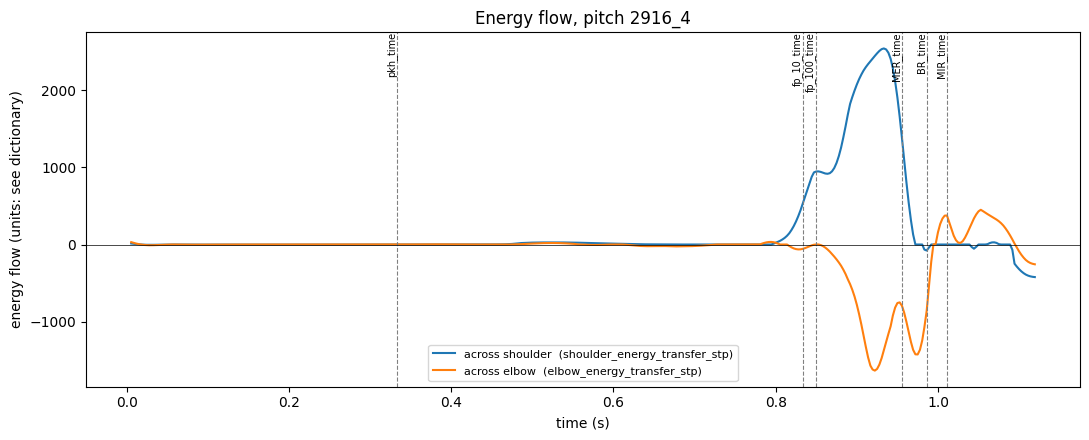

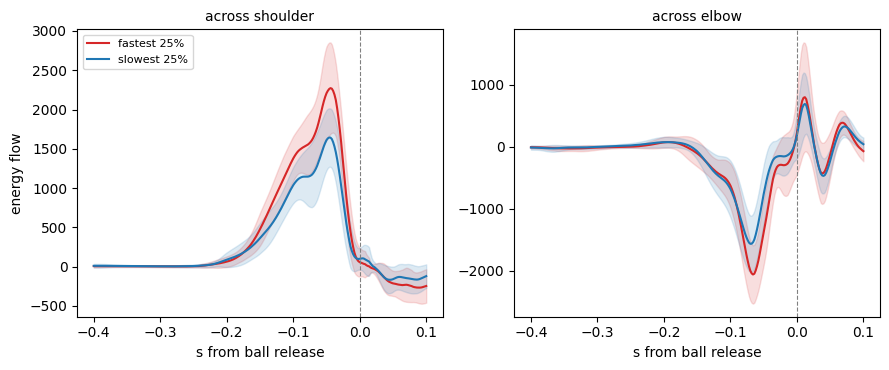

In [11]:
energy = load_table("energy_flow")
print(energy.shape)
print("Columns:", list(energy.columns))

# Edit these if the printout shows a better match
ENERGY = {
    "pelvis → trunk":          find_col(energy, "pelvis", "transfer"),
    "trunk → shoulder":        find_col(energy, "thorax", "transfer"),
    "across shoulder":         find_col(energy, "shoulder", "transfer", exclude=("glove",)),
    "across elbow":            find_col(energy, "elbow", "transfer", exclude=("glove",)),
}
print("Picked:", ENERGY)

one_e = energy[energy["session_pitch"] == pitch_id].sort_values("time")
fig, ax = plt.subplots(figsize=(11, 4.5))
for label, col in ENERGY.items():
    if col:
        ax.plot(one_e["time"], one_e[col], label=f"{label}  ({col})")
event_lines(ax, energy, pitch_id)
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("time (s)"); ax.set_ylabel("energy flow (units: see dictionary)")
ax.set_title(f"Energy flow, pitch {pitch_id}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fast_vs_slow(energy, ENERGY, "energy flow")

## 3. C3D: raw marker positions

Each C3D holds the 3D position of every reflective marker on the body in every frame. File names follow `USER_SESSION_HEIGHT_WEIGHT_PITCHNUMBER_PITCHTYPE_SPEED.c3d` (e.g. `..._FF_905.c3d` = 90.5 mph). Lab axes: +x from second base toward home plate, +y toward first base, +z up.

In [12]:
import ezc3d

pitch_files = [p for p in c3d_files if "_FF_" in p.name]   # skip static calibration files
path = pitch_files[0]
c = ezc3d.c3d(str(path))

pts = c["data"]["points"][:3]                      # (3, n_markers, n_frames)
labels = c["parameters"]["POINT"]["LABELS"]["value"]
rate = c["header"]["points"]["frame_rate"]
units = c["parameters"]["POINT"].get("UNITS", {}).get("value", ["?"])[0]
if units == "mm":
    pts = pts / 1000.0
print(f"{path.name}\n{len(labels)} markers | {pts.shape[2]} frames at {rate:.0f} Hz "
      f"({pts.shape[2] / rate:.2f} s) | units: {units} (shown in m)")
print("Markers:", labels)

000002_003034_73_207_002_FF_809.c3d
45 markers | 726 frames at 360 Hz (2.02 s) | units: m (shown in m)
Markers: ['C7', 'CLAV', 'LANK', 'LASI', 'LBHD', 'LELB', 'LFHD', 'LFIN', 'LFRM', 'LHEE', 'LKNE', 'LMANK', 'LMELB', 'LMKNE', 'LPSI', 'LSHO', 'LTHI', 'LTIB', 'LTOE', 'LUPA', 'LWRA', 'LWRB', 'RANK', 'RASI', 'RBAK', 'RBHD', 'RELB', 'RFHD', 'RFIN', 'RFRM', 'RHEE', 'RKNE', 'RMANK', 'RMELB', 'RMKNE', 'RPSI', 'RSHO', 'RTHI', 'RTIB', 'RTOE', 'RUPA', 'RWRA', 'RWRB', 'STRN', 'T10']


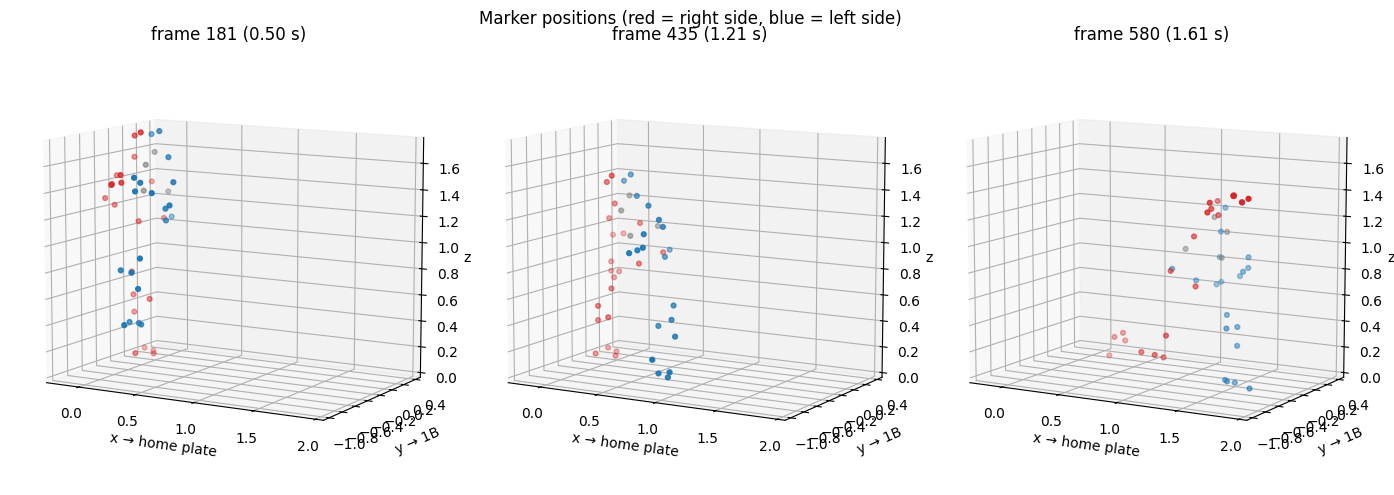

In [13]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

colors = ["tab:red" if l.upper().startswith("R") else
          "tab:blue" if l.upper().startswith("L") else "gray" for l in labels]
valid = ~np.isnan(pts).any(axis=(0, 1))          # frames with every marker present
lo, hi = np.nanmin(pts, axis=(1, 2)), np.nanmax(pts, axis=(1, 2))

def setup(ax):
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(hi - lo)
    ax.set_xlabel("x → home plate"); ax.set_ylabel("y → 1B"); ax.set_zlabel("z up")
    ax.view_init(elev=10, azim=-60)

fig = plt.figure(figsize=(14, 5))
for i, frac in enumerate([0.25, 0.6, 0.8]):
    f = int(frac * pts.shape[2])
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.scatter(*pts[:, :, f], c=colors, s=12)
    setup(ax); ax.set_title(f"frame {f} ({f / rate:.2f} s)")
plt.suptitle("Marker positions (red = right side, blue = left side)")
plt.tight_layout(); plt.show()

In [14]:
from matplotlib import animation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 60
STEP = 4                                          # every 4th frame (~90 fps playback source)
frames = range(0, pts.shape[2], STEP)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
setup(ax)
sc = ax.scatter(*pts[:, :, 0], c=colors, s=14)
title = ax.set_title("")

def update(f):
    sc._offsets3d = tuple(pts[:, :, f])
    title.set_text(f"{f / rate:.2f} s")
    return sc, title

anim = animation.FuncAnimation(fig, update, frames=frames, interval=40)
plt.close(fig)
HTML(anim.to_jshtml())

Output hidden; open in https://colab.research.google.com to view.

## 4. Stick figure

Markers sit on the skin, so a joint is approximated by averaging the markers around it (for example, the elbow = mean of the elbow markers on that side). Markers are assigned to joints by matching their names against the keywords in `JOINT_TOKENS`; the printout shows which markers went where. If a joint is missing or wrong, add the right marker names from the marker list above.

In [15]:
# Keywords searched in the marker name after its first letter (R/L side).
# Checked in this order; a marker goes to the first joint that matches.
JOINT_TOKENS = {
    "head":     ["HEAD", "FHD", "BHD"],
    "heel":     ["HEE", "HEEL"],
    "toe":      ["TOE", "MT"],
    "wrist":    ["WRA", "WRB", "WR", "RSP", "USP"],
    "hand":     ["HAND", "FIN", "MCP"],
    "elbow":    ["ELB", "LEL", "MEL", "EL"],
    "shoulder": ["SHO", "ACR"],
    "hip":      ["ASI", "PSI", "GT", "HIP"],
    "knee":     ["KNE", "KNEE"],
    "ankle":    ["ANK", "MAL"],
}
CENTER_HEAD = {"HEAD", "FHD", "BHD"}   # head markers on both sides -> one head point

def assign(labels):
    groups = {}
    for i, lab in enumerate(labels):
        u = lab.upper()
        side, rest = (u[0], u[1:]) if len(u) > 1 and u[0] in "RL" else ("", u)
        for joint, toks in JOINT_TOKENS.items():
            if any(t in rest for t in toks):
                key = "head" if joint == "head" else (f"{side}_{joint}" if side else None)
                if key:
                    groups.setdefault(key, []).append(i)
                break
    return groups

groups = assign(labels)
for k in sorted(groups):
    print(f"{k:<12} <- {[labels[i] for i in groups[k]]}")
unused = sorted(set(range(len(labels))) - {i for v in groups.values() for i in v})
print("\nNot used:", [labels[i] for i in unused])

J = {k: np.nanmean(pts[:, idx, :], axis=1) for k, idx in groups.items()}   # each (3, n_frames)
if "R_shoulder" in J and "L_shoulder" in J:
    J["neck"] = (J["R_shoulder"] + J["L_shoulder"]) / 2
if "R_hip" in J and "L_hip" in J:
    J["pelvis"] = (J["R_hip"] + J["L_hip"]) / 2

BONES = [("head", "neck"), ("R_shoulder", "L_shoulder"), ("R_hip", "L_hip"),
         ("neck", "pelvis")]
for s in "RL":
    BONES += [(f"{s}_shoulder", f"{s}_elbow"), (f"{s}_elbow", f"{s}_wrist"),
              (f"{s}_wrist", f"{s}_hand"), (f"{s}_shoulder", f"{s}_hip"),
              (f"{s}_hip", f"{s}_knee"), (f"{s}_knee", f"{s}_ankle"),
              (f"{s}_ankle", f"{s}_heel"), (f"{s}_ankle", f"{s}_toe"), (f"{s}_heel", f"{s}_toe")]
BONES = [b for b in BONES if b[0] in J and b[1] in J]
print(f"\n{len(BONES)} bones drawn")
if len(BONES) < 8:
    print("Few bones found: edit JOINT_TOKENS using the marker list printed earlier.")

def bone_color(a, b):
    side = (a[0] if a[:2] in ("R_", "L_") else b[0] if b[:2] in ("R_", "L_") else "")
    return {"R": "tab:red", "L": "tab:blue"}.get(side, "black")

L_ankle      <- ['LANK', 'LMANK']
L_elbow      <- ['LELB', 'LMELB']
L_hand       <- ['LFIN']
L_heel       <- ['LHEE']
L_hip        <- ['LASI', 'LPSI']
L_knee       <- ['LKNE', 'LMKNE']
L_shoulder   <- ['LSHO']
L_toe        <- ['LTOE']
L_wrist      <- ['LWRA', 'LWRB']
R_ankle      <- ['RANK', 'RMANK']
R_elbow      <- ['RELB', 'RMELB']
R_hand       <- ['RFIN']
R_heel       <- ['RHEE']
R_hip        <- ['RASI', 'RPSI']
R_knee       <- ['RKNE', 'RMKNE']
R_shoulder   <- ['RSHO']
R_toe        <- ['RTOE']
R_wrist      <- ['RWRA', 'RWRB']
head         <- ['LBHD', 'LFHD', 'RBHD', 'RFHD']

Not used: ['C7', 'CLAV', 'LFRM', 'LTHI', 'LTIB', 'LUPA', 'RBAK', 'RFRM', 'RTHI', 'RTIB', 'RUPA', 'STRN', 'T10']

22 bones drawn


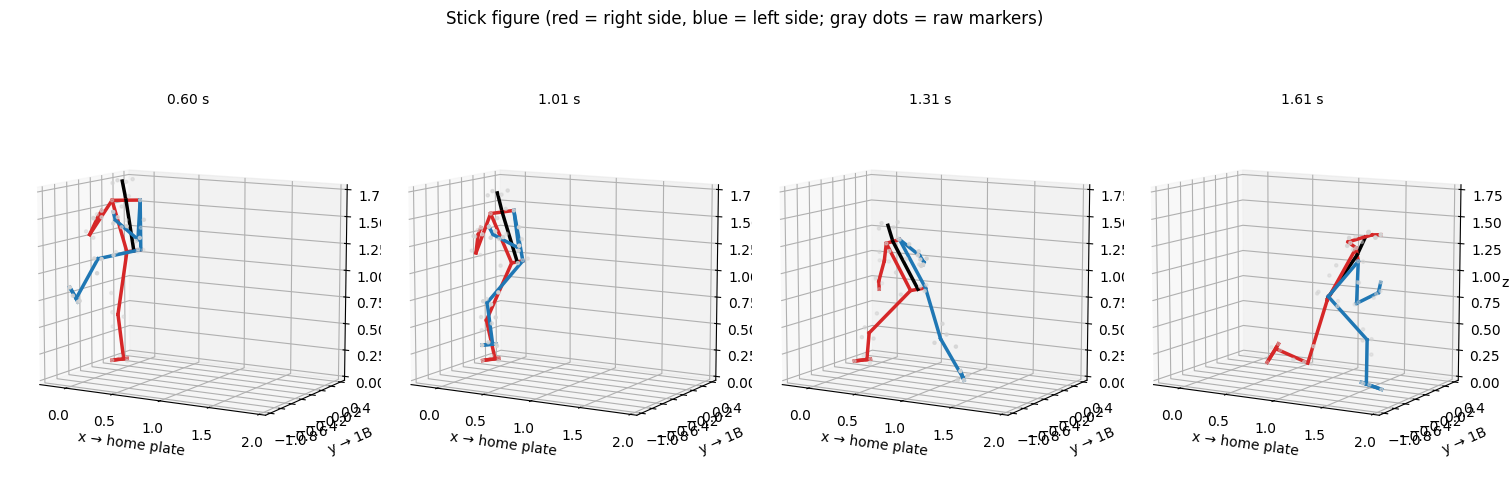

In [16]:
fig = plt.figure(figsize=(15, 5.5))
for i, frac in enumerate([0.3, 0.5, 0.65, 0.8]):
    f = int(frac * pts.shape[2])
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.scatter(*pts[:, :, f], c="lightgray", s=5)
    for a, b in BONES:
        ax.plot(*np.c_[J[a][:, f], J[b][:, f]], color=bone_color(a, b), lw=2.5)
    setup(ax); ax.set_title(f"{f / rate:.2f} s", fontsize=10)
plt.suptitle("Stick figure (red = right side, blue = left side; gray dots = raw markers)")
plt.tight_layout(); plt.show()

In [17]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
setup(ax)
dots = ax.scatter(*pts[:, :, 0], c="lightgray", s=5)
lines = [ax.plot([], [], [], color=bone_color(a, b), lw=2.5)[0] for a, b in BONES]
title = ax.set_title("")

def update_stick(f):
    dots._offsets3d = tuple(pts[:, :, f])
    for ln, (a, b) in zip(lines, BONES):
        seg = np.c_[J[a][:, f], J[b][:, f]]
        ln.set_data_3d(seg[0], seg[1], seg[2])
    title.set_text(f"{f / rate:.2f} s")
    return [dots, title, *lines]

anim_stick = animation.FuncAnimation(fig, update_stick, frames=range(0, pts.shape[2], STEP), interval=40)
plt.close(fig)
HTML(anim_stick.to_jshtml())

Output hidden; open in https://colab.research.google.com to view.

## 5. Column definitions and sign conventions

The repository documents every variable. These cells show the documentation directly from your clone, so it always matches the data version you downloaded.

In [18]:
from IPython.display import Markdown, display

dict_path = next(iter(sorted((REPO / "baseball_pitching" / "data").glob("data_dictionary*.csv"))), None)
if dict_path is None:
    print("No data_dictionary.csv found; see data_dictionary.json at the repository root.")
else:
    dd = pd.read_csv(dict_path)
    print(dict_path.relative_to(REPO), dd.shape)
    print("Dictionary columns:", list(dd.columns))
    name_col = next((c for c in dd.columns if c.lower() in ("column", "variable", "name", "field")), dd.columns[0])

    def describe(cols):
        # dictionary rows for a list of column names (e.g. the signals picked above)
        return dd[dd[name_col].isin(cols)]

    picked = [c for c in {**SEGMENTS, **ANGLES, **ENERGY}.values() if c]
    display(describe(picked))

baseball_pitching/data/data_dictionary.csv (91, 6)
Dictionary columns: ['dataset', 'column', 'dtype', 'example', 'description', 'documented']


,dataset,column,dtype,example,description,documented


In [19]:
# Sign conventions for joint angles, forces and moments (from baseball_pitching/README.md)
readme = (REPO / "baseball_pitching" / "README.md").read_text()
start, end = readme.find("# Full Signal"), readme.find("# Point of Interest")
display(Markdown(readme[start:end] if start != -1 else readme))

# Full Signal

We first calculate joint angles, velocities, forces, and moments according to the right hand rule. We then perform select adjustments to better match coach/player intuition (righty/lefty symmetry, sign negations, adding or subtracting 90 degrees, etc.). Forces and Moments are internal forces and moments.

Below is a list of joint mechanics, their components, and conventions. Where joint kinematics are constrained by the model, corresponding kinetic conventions are provided. 

## Processed Joint Kinematic/Kinetic Conventions

Processed full signal data were filtered with a 4th order Butterworth low pass filter with a cutoff frequency of 20.0 Hz.

### Kinematics (Joint Angles, Joint Velocities)

| Joint | C1 (”_X”) | C2 (”_Y”) | C3 (”_Z”) |
| --- | --- | --- | --- |
| Wrist | Extension (+)/Flexion (-) | Ulnar (+)/Radial (-) Deviation | Constrained |
| Elbow | Flexion (+)/Extension (-) | Constrained | Pronation (+)/Supination (-) |
| Shoulder | Horizontal Ab (+)/Adduction (-) | Add (+)/Abduction (-) | External (+)/Internal (-) Rotation |
| Pelvis | Anterior (+)/Posterior (-) Tilt | Throwing Side (+)/Glove Side (-) Hip Hike (Lateral Flexion) | Axial Rotation Towards (+)/Away (-) from home plate |
| Torso | Flexion (+)/Extension (-) | Glove Side (+)/Throwing Side (-) Lateral Flexion | Axial Rotation Towards (+)/Away (-) from home plate |
| Torso-Pelvis | Extension (+)/Flexion (-) | Glove Side (+)/Throwing Side (-) Lateral Flexion | Hip-Shoulder Separation (+)/Closing (-) |
| Hip | Extension (+)/Flexion (-) | Ab (+)/Adduction (-) | External (+)/Internal (-) Rotation |
| Knee | Flexion (+)/Extension (-) | Constrained | Constrained |
| Ankle | Dorsi (+)/Plantar (-) Flexion | Ab (+)/Adduction (-) | Inversion (+)/Eversion (-) |

### Forces

| Joint | C1 (”_X”) | C2 (”_Y”) | C3 (”_Z”) |
| --- | --- | --- | --- |
| Wrist | Lateral (+)/ Medial(-) | Anterior (+)/Posterior (-) | Compression (+)/Distraction (-) |
| Elbow | Lateral (+)/ Medial (-) | Anterior (+)/ Posterior (-) | Compression (+)/Distraction (-) |
| Shoulder | Rel. upper arm: — (convention not reported) Rel. thorax: Lateral (+)/Medial (-) | Rel. upper arm: — (convention not reported) Rel. thorax: Anterior (+)/Posterior (-) | Rel upper arm: Compression (+)/Distraction (-). Rel thorax: Superior (+)/Inferior (-) |
| Pelvis | NA | NA | NA |
| Torso | NA | NA | NA |
| Torso-Pelvis | NA | NA | NA |
| Hip | Rel thigh: — (convention not reported) Rel pelvis: Lateral (+)/Medial (-) | Rel thigh: — (convention not reported) Rel pelvis: Anterior (+)/Posterior (-) | Rel thigh: Compression (+)/Distraction (-). Rel pelvis: Superior (+)/Inferior (-) |
| Knee | Lateral (+)/Medial (-) | Anterior (+)/Posterior (-) | Compression (+)/Distraction (-) |
| Ankle | Lateral (+)/Medial (-) | Anterior (+)/Posterior (-) | Superior (+)/Inferior (-) |

### Moments

| Joint | C1 (”_X”) | C2 (”_Y”) | C3 (”_Z”) |
| --- | --- | --- | --- |
| Wrist | Flexion (+)/Extension (-) | Ulnar (+)/Radial (-) Deviation | NA |
| Elbow | Flexion (+)/Extension (-) | Varus (+)/Valgus (-) | Pronation (+)/Supination (-) |
| Shoulder | Rel upper arm: — (convention not reported) Rel thorax: — (convention not reported) | Rel upper arm: — (convention not reported) Rel. thorax: Ab (+)/ Adduction (-) | Rel upper arm: Internal (+)/External (-) Rotation. Rel thorax: Horizontal Add (+)/Abduction (-) |
| Pelvis | NA | NA | NA |
| Torso | NA | NA | NA |
| Torso-Pelvis | NA | NA | NA |
| Hip | Rel thigh: — (convention not reported) Rel pelvis: Extension (+)/Flexion (-) | Rel thigh: — (convention not reported) Rel pelvis: — (convention not reported) | Rel thigh: Internal (+)/External (-) Rotation. Rel pelvis: — (convention not reported) |
| Knee | Flexion (+)/Extension (-) | Varus (+)/Valgus (-) | External (+)/Internal (-) Rotation |
| Ankle | Plantar (+)/Dorsi (-) Flexion | Eversion (+)/Inversion (-) | Ab(+)/Adduction (-) |

## Processed Ground Reaction Force Conventions

Ground reaction force data were filtered with a 4th order Butterworth low pass filter with a cutoff frequency of 40.0 Hz

| Force Plate | X | Y | Z |
| --- | --- | --- | --- |
| FP1/3 | + = Braking (Posterior) | + = Lateral | + = Superior |
| FP2 | + = Push off (Anterior) | + = Lateral | + = Superior |

## Table Schema

Full signal data are broken up into six large CSV files:

- `energy_flow`: energy transfer, energy generation, energy absorption
- `force_plate`: rear leg, lead leg ground reaction forces
- `forces_moments`: joint forces, joint moments
- `joint_angles`: joint angles
- `joint_velos`: joint angular velocities
- `landmarks`: joint center positions

Tables may be joined using `session_pitch` + `time`. Please note that force plate and marker-derived data are provided at their own respective measurement rates (1,080 Hz and 360 Hz, respectively). Therefore, we recommend caution when joining force plate and marker-derived data to avoid potential data loss.

The times at which common events occurred are also joined in each table for convenience. Provided events are foot contact (10% bodyweight), foot plant (100% bodyweight), maximum external rotation (layback), ball release, and maximum internal rotation.

By default, forces and moments are expressed in the proximal segment’s coordinate system (ex. `lead_ankle_moment_x` represents the moment at the lead ankle about the shank’s x-axis). Exceptions are made for the forces and moments at the shoulders and hips. For these joints, two sets of forces and two sets of moments are provided. The first set is the joint force/moment resolved in the proximal segment’s coordinate system (ex. shoulder force along the thorax’s x, y, and z axes). The second set is the joint force/moment resolved in the distal segment’s coordinate system (ex. shoulder force along the upper arm’s x, y, and z axes). For these “double dipped” joint kinetics, we follow the naming convention `joint_referenceSegment_kineticType_element`. For example, `shoulder_upper_arm_moment_z` represents the moment at the shoulder about the upper arm’s longitudinal (z) axis and `shoulder_thorax_moment_z` represents the moment at the shoulder resolved about the thorax superior-inferior (z) axis.

One potential research project is to process the provided C3D using your own pipeline and compare your results with ours. Self-processed data from C3D files may be linked to the provided full-signal data through [`data/metadata.csv`](data/metadata.csv).

## metadata.csv Schema

[`data/metadata.csv`](data/metadata.csv) links the C3D files to the POI and full-signal data and provides athlete- and session-level information.

- `user`: athlete ID
- `session`: session ID
- `session_pitch`: unique pitch ID (joins to the POI and full-signal data)
- `session_mass_kg`: body mass (kg)
- `session_height_m`: body height (m)
- `age_yrs`: age at collection (years)
- `playing_level`: playing level at the time of data collection
- `pitch_speed_mph`: pitch speed (miles per hour)
- `filename_new`: anonymized c3d filename
- `modelname_new`: anonymized static model c3d filename



In [20]:
# Dataset background: who was measured, how, known limitations
display(Markdown((REPO / "DATASHEET.md").read_text()))

# Datasheet for the OpenBiomechanics Project (OBP)

This datasheet follows the structure proposed in *Datasheets for Datasets* (Gebru et al., 2018). It documents the OpenBiomechanics Project dataset released by Driveline Baseball Research & Development. All composition statistics below were computed directly from the in-repository point-of-interest (POI) and metadata CSVs; the exact pandas snippet used is included at the end of this document.

The dataset comprises three data modules — **Baseball Pitching**, **Baseball Hitting**, and **High Performance** — plus supporting computer-vision and tutorial material.

---

## Motivation

**For what purpose was the dataset created?**
The OpenBiomechanics Project was created by [Driveline Baseball Research & Development](https://drivelinebaseball.com/mission-and-purpose/) to provide raw (cleaned C3D marker files) and processed (full-signal time series + point-of-interest summaries) sports-biomechanics data to the general public. The goal is to lower the barrier to biomechanics research in baseball by openly distributing marker-based motion-capture, force-plate, and physical-assessment data that are otherwise difficult and expensive to collect. Project homepage: [openbiomechanics.org](https://openbiomechanics.org).

**Who created the dataset and who funded it?**
The dataset was created and funded by Driveline Baseball's Research & Development group.

---

## Composition

**What do the instances represent?**
Instances are individual baseball movement trials (pitches or swings) and athlete-level physical-assessment records. Each pitching/hitting trial is linked to marker-derived kinematics/kinetics and, where applicable, ground reaction forces. High-performance records are per-assessment force-plate and range-of-motion summaries.

### Baseball Pitching (fastball trials)

Computed from `baseball_pitching/data/poi/poi_metrics.csv` (411 rows) and `baseball_pitching/data/metadata.csv` (411 rows):

- **Pitch trials:** 411
- **Unique athletes** (`user`): 100
- **Unique sessions:** 100
- **Pitch type:** all 411 trials are fastballs (`FF`)
- **Handedness:** 328 right-handed, 83 left-handed
- **Pitch speed (mph):** min 69.5 / median 85.3 / max 94.4
- **Athlete age at collection (years):** min 17.7 / median 20.7 / max 27.6
- **Playing-level breakdown** (`playing_level`):

  | Playing level | Trials |
  | --- | --- |
  | College | 314 |
  | Independent | 42 |
  | High school | 32 |
  | MiLB | 23 |

### Baseball Hitting (swing trials)

Computed from `baseball_hitting/data/poi/poi_metrics.csv` (677 rows) and `baseball_hitting/data/metadata.csv` (677 rows):

- **Swing trials:** 677
- **Unique athletes** (`user`): 98
- **Unique sessions:** 98
- **Hitting side:** 496 right-handed, 181 left-handed
- **Exit velocity (mph):** min 48.8 / median 91.0 / max 107.0
- **Athlete age at collection (years):** min 17 / median 20 / max 31
- **Paired HitTrax ball-in-play records:** 604 rows (`baseball_hitting/data/poi/hittrax.csv`)
- **Playing-level breakdown** (`highest_playing_level`):

  | Playing level | Trials |
  | --- | --- |
  | College | 517 |
  | High school | 83 |
  | MiLB | 47 |
  | Independent | 30 |

### High Performance (force-plate + physical assessment)

Computed from `high_performance/data/hp_obp.csv`:

- **Assessment records:** 1,934
- **Unique athletes** (`athlete_uid`): 1,162
- **Playing-level breakdown** (`playing_level`): College 904, High School 816, Pro 214
- **Force-plate / assessment tests present** (by column suffix, with count of records containing data for each):

  | Test | Abbreviation | Records with data |
  | --- | --- | --- |
  | Countermovement Jump | CMJ | 1,913 |
  | Squat Jump | SJ | 1,827 |
  | Repeated Hop Test | HT | 1,803 |
  | Isometric Mid-Thigh Pull | IMTP | 1,518 |
  | Plyo Pushup | PP | 438 |

  The module also includes table range-of-motion (thoracic-spine mobility) and supine shoulder internal/external-rotation strength (dynamometer) measurements. The Plyo Pushup is not present for the entire dataset (438 of 1,934 records).

**Does the dataset contain all possible instances or a sample?**
The dataset is a sample of athletes assessed at Driveline Baseball facilities. Most participants are collegiate-level. The pitching module is restricted to fastball trials.

**What data does each instance consist of?**
Three representations are provided:

1. **Raw:** cleaned C3D marker files (per-athlete folders, with static model files). Pitching uses a marker set with three embedded force plates under the mound turf; hitting uses a marker set plus a 10-marker bat rigid body and four force plates under the batter's box. See each module README for marker-set images, global coordinate systems, and force-plate layouts.
2. **Full signal:** filtered joint angles, joint velocities, joint forces/moments, energy-flow, ground reaction forces, and landmark (joint-center) time series. Kinematics/kinetics are computed by the right-hand rule with coach/player-intuition sign adjustments, then filtered with a 4th-order Butterworth low-pass filter (20 Hz for marker-derived signals, 40 Hz for ground reaction forces). Marker-derived data sampled at 360 Hz; force-plate data at 1,080 Hz.
3. **Point of interest (POI):** one-row-per-trial summary metrics (e.g., peak shoulder internal-rotation velocity, elbow varus moment, stride length, ground-reaction-force peaks for pitching; bat speed, attack angle, hip-shoulder separation for hitting). Full variable dictionaries are in the module READMEs.

**Is there a label or target?**
There is no single target. Common outcome variables are `pitch_speed_mph` (pitching) and `exit_velo_mph_x` (hitting). The High Performance module additionally links pitching/hitting performance (e.g., `pitch_speed_mph`, `bat_speed_mph`) to force-plate metrics.

**Are relationships between instances made explicit?**
Yes. Trials link to athletes and sessions via `user` / `session`, and to full-signal/POI data via `session_pitch` (pitching) or `session_swing` (hitting). Full-signal tables join on `session_pitch`/`session_swing` + `time`. Event times (foot contact, foot plant, maximum external rotation, ball release, maximum internal rotation for pitching; front foot contact, front foot plant, contact for hitting) are joined into each table for convenience.

**Are there recommended data splits?**
No canonical train/test split is defined. Users should account for repeated measures — multiple trials per athlete and per session — when constructing splits to avoid athlete leakage.

**Are there errors, sources of noise, or redundancies?**
The data are marker-based motion capture and are subject to normal soft-tissue-artifact and modeling limitations. Some legacy markers (LIC/RIC iliac-crest markers) are no longer used and may be absent in some C3D files; RKNEE2/LKNEE2 are labeled RMKNE/LMKNE. Some force/moment sign conventions at the shoulder and hip are not reported (noted as "convention not reported" in the module tables). The Plyo Pushup test is missing for most High Performance records. Caution is advised when joining force-plate (1,080 Hz) and marker-derived (360 Hz) data because of the differing sample rates.

**Is the dataset self-contained?**
The POI and metadata CSVs are in-repo. The large raw C3D files and full-signal archives are **not** stored in git; they are distributed via GitHub Releases (see Distribution).

**Does the dataset contain confidential or sensitive data?**
Athlete identifiers are anonymized (numeric `user`/`session` IDs, UUID `athlete_uid` in the High Performance module, and anonymized C3D filenames). The data are human-subjects biomechanics measurements collected under IRB approval (see Collection Process). No names or direct identifiers are included.

---

## Collection Process

**How was the data acquired?**
Marker-based optical motion capture was collected at Driveline Baseball facilities. Pitching trials were thrown on an instrumented mound with three force plates embedded under the turf (average turf thickness ~0.5 in). Hitting trials were collected in an instrumented batter's box with four force plates under the turf; hitters started with one or both feet on the back plate and landed with the lead leg on the front plate.

**Hitting stimulus (pitching-machine setup):** all swings were collected while hitting off a pitching machine set at ~65 mph from ~40 ft from home plate.

High-performance data were collected using force-plate protocols — Countermovement Jump, Squat Jump, Isometric Mid-Thigh Pull, Repeated Hop Test, and Plyo Pushup — paired with table range-of-motion and dynamometer shoulder-strength testing. Protocol videos are linked in the High Performance README.

**Who was involved and over what timeframe?**
Data were collected by Driveline Baseball R&D staff. High Performance assessment dates in the data span at least 2021 onward (see the `test_date` column).

**Were the individuals notified and did they consent? Was there ethical review?**
Yes. Western IRB (WCG IRB) provided ethical approval for all data-collection procedures under **Western IRB # WB-DLR-115**.

---

## Preprocessing / Cleaning / Labeling

**Was preprocessing done?**
Yes. C3D files were cleaned and organized into per-athlete folders with static model files. Full-signal joint angles, velocities, forces, and moments were computed by the right-hand rule and then adjusted for coach/player intuition (righty/lefty symmetry, sign negations, ±90° offsets). Marker-derived signals were filtered with a 4th-order Butterworth low-pass filter at 20 Hz; ground reaction forces at 40 Hz. Forces and moments are internal and, by default, expressed in the proximal segment's coordinate system, with dual-resolved ("double-dipped") kinetics provided at the shoulders and hips. POI metrics were extracted at defined biomechanical events.

**Was the raw data saved?**
Yes. Cleaned C3D files are provided so users can run their own pipeline start-to-finish and link results to the provided full-signal data via the metadata CSV.

---

## Uses

**What has the dataset been used for / could it be used for?**
Baseball pitching and hitting biomechanics research; force-plate/performance analytics; computer-vision and markerless-pose work (see the Computer Vision module); and methodological studies (e.g., processing the provided C3D through a custom pipeline and comparing against the released full-signal data).

**What should users be aware of?**
Users should respect the repeated-measures structure (multiple trials per athlete/session), the differing sample rates of force-plate vs. marker data, the fastball-only scope of the pitching module, the predominantly collegiate population, and the missing Plyo Pushup data in the High Performance module.

**Are there tasks for which the dataset should not be used?**
Any commercial use is prohibited by the data license (see Distribution). The license additionally forbids use by any employee, contractor, associate, or significant shareholder of a professional sports organization or financial-analysis firm without a separate written commercial license.

---

## Distribution

**How is the dataset distributed?**
The dataset is distributed publicly through the OpenBiomechanics GitHub repository and [GitHub Releases](https://github.com/drivelineresearch/openbiomechanics/releases):

- **POI + metadata CSVs** remain in-repo under each module's `data/` folder, so summary analyses work without downloading the large archives.
- **Raw C3D files and full-signal tables are NOT stored in git.** They are distributed as release assets:
  - `dataset-v1` — processed full-signal archives (pitching + hitting) plus raw `pitching_c3d.zip` and `hitting_c3d.zip`.
  - `cv-media-v1` — `cv_media.zip`, computer-vision demo media.
  - `tools-mokka-0.6.2` — Mokka installers for viewing C3D files.
- Full-signal tables ship as `.zip` archives (e.g., `joint_angles.zip`) and must be unzipped before use.
- Run `scripts/download_data.sh` from the repository root to verify and place the release assets. C3D archives are extracted; full-signal archives remain zipped until the user selects tables to extract.

**License.**
OBP is dual-licensed:

- **Code** — MIT License (`LICENSE-CODE.md`).
- **Data + biomechanics documentation** — Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International (**CC BY-NC-SA 4.0**; `LICENSE-DATA.md`).

The data license is non-commercial and carries one additional exclusion beyond standard CC BY-NC-SA terms: any employee or contractor employed by, associated with, or a significant shareholder of a professional sports organization or financial-analysis firm is forbidden from using OBP data for any purpose without a separate written commercial (paid) license. See `LICENSE-DATA.md` for the full terms.

---

## Maintenance

**Who maintains the dataset?**
Driveline Baseball Research & Development maintains the dataset via the public GitHub repository.

**How is it versioned and updated?**
Updates are recorded in the root `README.md` and released through GitHub Releases (current data tag: `dataset-v1`). Notable updates include the Computer Vision module (2023-11-02), the High Performance module (2024-07-30), and the validated provisional OBP-CV calibration audit with source provenance and held-out diagnostics (2026-07-19).

**How can users contribute or report issues?**
Contributions and issues are handled through the GitHub repository (see `CONTRIBUTING.md`). For more information, visit [openbiomechanics.org](https://openbiomechanics.org).

---

## Reproducing the Composition Statistics

All Composition numbers above were computed with the following pandas snippet, run against the in-repo CSVs:

```python
import pandas as pd, re

# Pitching
pm = pd.read_csv("baseball_pitching/data/poi/poi_metrics.csv")
pmeta = pd.read_csv("baseball_pitching/data/metadata.csv")
len(pm)                                  # 411 trials
pmeta['user'].nunique()                  # 100 athletes
pmeta['playing_level'].value_counts()    # college 314, independent 42, high_school 32, milb 23
pm['pitch_speed_mph'].agg(['min','median','max'])   # 69.5 / 85.3 / 94.4

# Hitting
hm = pd.read_csv("baseball_hitting/data/poi/poi_metrics.csv")
hmeta = pd.read_csv("baseball_hitting/data/metadata.csv")
len(hm)                                  # 677 trials
hmeta['user'].nunique()                  # 98 athletes
hmeta['highest_playing_level'].value_counts()  # college 517, high_school 83, milb 47, independent 30
hm['exit_velo_mph_x'].agg(['min','median','max'])   # 48.8 / 91.0 / 107.0
len(pd.read_csv("baseball_hitting/data/poi/hittrax.csv"))  # 604 HitTrax rows

# High Performance
hp = pd.read_csv("high_performance/data/hp_obp.csv")
len(hp)                                  # 1934 records
hp['athlete_uid'].nunique()              # 1162 athletes
hp['playing_level'].value_counts()       # College 904, High School 816, Pro 214
for suf in ['cmj','sj','ht','imtp','pp']:
    cols = [c for c in hp.columns if c.endswith('_'+suf)]
    print(suf, hp[cols].notna().any(axis=1).sum())  # cmj 1913, sj 1827, ht 1803, imtp 1518, pp 438
```


## Next steps
- `forces_moments`, `force_plate` and `landmarks` load the same way (`load_table("forces_moments")`). `landmarks` holds computed joint-center positions, which would give a more accurate stick figure than averaged skin markers.
- Build the fast vs. slow "ghost" delivery: time-normalize each pitch's joint positions and average them within each group.